<a href="https://colab.research.google.com/github/johnryantaylor/QCES/blob/main/Project1_numerical_methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: Heat transport

In this project we will discretize and timestep two systems that describe heat transport. In the first part we will timestep a box model for the Earth's surface temperature with heat buffering provided by the deep ocean. In the second part, we will timestep the one-dimensional diffusion equation which can be used to describe heat moving through a medium (e.g. the ground or still air and water).

Through this project, we will learn how to efficiently timestep ordinary and partial differential equations and examine errors introduced by the numerical discretization. We will also have the chance to explore the timescales and physical processes involved in heat transport in the climate system.

## 1. Climate box model

In this part of the project we will timestep the following box model.

$$ C_s \partial_t T = F(t) - \gamma(T-\theta) $$

$$ C_d \partial_t \theta = \gamma (T-\theta) $$

Here, $T(t)$ represents the global mean surface temperature as a function of time and $\theta(t)$ is the temperature of the deep ocean, both expressed as the difference between the temperature and a pre-industrial equilibrium in units of $^\circ K$. The net surface heat flux, $F(t)$, drives departures from the pre-industrial temperatures. The heat flux between the surface and deep ocean is assumed to be proportional to the difference between the surface and deep ocean temperatures. The constants are the heat capacity of the surface of the Earth, $C_s$, the heat capacity of the deep ocean, $C_d$, and the heat flux coefficient, $\gamma$, all given in units of $W/^\circ K/m^2$. Note that $C_s$ and $C_d$ (as defined in Nicklas et al. 2025) are heat capacities per year; i.e. $1/C_s$ tells us how much the surface temperature would increase if a flux of 1 $W/m^2$ were applied for one year.

This model is inspired by a more complicated version of a two box climate model in the paper referenced below. (Interested students might consider adding some additional features from their model, but this is not required for this project).

*Nicklas, J.M., Fox-Kemper, B. and Lawrence, C., 2025. Efficient Estimation of Climate State and Its Uncertainty Using Kalman Filtering with Application to Policy Thresholds and Volcanism. Journal of Climate, 38(5), pp.1235-1270.*

Below, we start to build code to solve these equations. Execute the code cells below.  In some cases you will be asked to add code.

Student tasks are in [Section 1.1](#section1pt1), [Section 1.2](#section1pt2), and [Section 1.3](#section1pt3).

In [151]:
# Before we start, import necessary libraries. Run this cell first.
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time

Now, let's define values for the various constants. These values are taken from Nicklas et al., 2025.

In [152]:
C_s = 17 # heat capacity of the Earth's surface (W/m^2/K)
C_d = 156 # heat capacity of the deep ocean (W/m^2/K)
gamma = 0.67 # heat exchange coefficient between surface and deep ocean (W/m^2/K)

Now, let's define a function for F(t), the net surface heat flux (in units of $W/m^2$) that will force our model. This function is here to represent the heat imbalance caused by antropogenic greenhouse gases in the atmosphere. When $F=0$, there is no net surface heat flux. The argument, $t$, is the time in years. We will let $t=0$ denote the start of our additional warming, and we set $F=1$ if $t<200$ years and $F=0$ if $t>200$ years. This corresponds to a very bad-case emissions scenario with an abrupt drop in emissions after 200 years.

In [153]:
def F(t):
    return 1 if t < 200 else 0

Next, set the initial conditions. We will use arrays `T` and `theta`. `T[i]` represents the ith value in the array. We will use `T[0]` and `theta[0]` to hold the initial conditions. Subsequent values, `T[2]`, `T[3]`, etc. will be determined by timestepping the equations. We start by initializing the arrays using numpy and filling them with zeros and then set the initial values (this isn't necessary here since our values are zero anyway, but the code is here to that you can change the initial conditions easily)

In [154]:
Nt = 500 # number of time steps (including the starting point)
T = np.zeros(Nt) # surface temperature array
theta = np.zeros(Nt) # deep ocean temperature array
T[0] = 0 # initial surface temperature anomaly (ºK)
theta[0] = 0 # initial deep ocean temperature anomaly (ºK)

Now, create an array with the time (in years) corresponding to each time index. Also, calculate the timestep, `dt`.

In [155]:
t = np.linspace(0, 500, Nt) # time in years.  This starts at 0 and ends at 500, with Nt total points
dt = t[1] - t[0] # timestep in years

Finally, we are ready to create a for loop to timestep the equations listed at the top of the section.

### 1.1 Student task:
<a id='section1pt1'></a>
Fill in the interior of the for loop to timestep the equations from the start of Section 1 using the Explicit Euler method.

In [156]:
for i in range(0, Nt-1):
    T[i+1] = T[i] + dt * ((F(t[i]) - gamma * (T[i] - theta[i]))/C_s)
    theta[i+1] = theta[i] + dt * ((gamma * (T[i] - theta[i]))/C_d)

After you are finished, run the cell below to plot the results

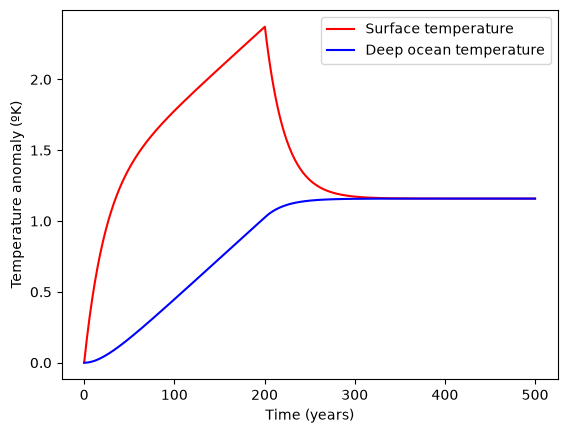

In [157]:
plt.plot(t,T,'r-')
plt.plot(t,theta,'b-')
plt.legend(['Surface temperature','Deep ocean temperature'])
plt.xlabel('Time (years)')
plt.ylabel('Temperature anomaly (ºK)')
plt.show()

### 1.2 Student task
<a id='section1pt2'></a>
Discuss the rates of change the temperature of the Earth's surface and the deep ocean at the start of the model run.  Can you explain the response of $T$ and $\theta$ to the forcing by defining characteristic timescales from the box model equations?

In [158]:
# defining characteristic timescales from the form of solution exp^(t/tau)
tau_s = C_s / gamma
tau_d = C_d / gamma

print(f"surface characteristic timescale = {tau_s:.2f} years")
print(f"deep ocean characteristic timescale = {tau_d:.2f} years")

surface characteristic timescale = 25.37 years
deep ocean characteristic timescale = 232.84 years


The surface has a much larger rate of change in the start of the model run than the deep ocean. This reflects the deep oceans much larger heat capacity (C_d) compared to the surface (C_s). As well as the characteristic timescales involved in the equations. The surface reaches 63% of its equilibrium value in 25 years whereas the deep ocean does this in ~ 230 years. Since the forcing is only from 0 < t < 200 years then the deep ocean will take longer to repond and longer to recover.

### 1.3 Student task
<a id='section1pt3'></a>
Modify the forcing function, `F(t)` above with 2-3 scenarios of your choice. Plot the temperature response for each scenario and briefly (2-3 sentences each) describe the temperature responses in each scenario. You will need to replicate some of the code blocks above so that you can produce a new set of plots below.

Forcing scenario 1: 
Let's have linearly increasing forcing for 200 years, then see how it recovers with an arbupt stop (i.e. F(t > 200) = 0)

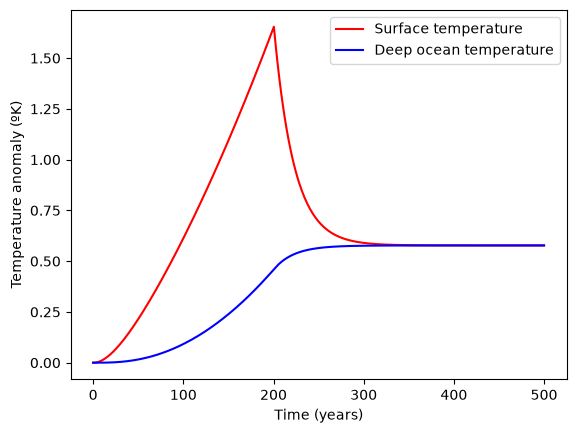

In [159]:
# scenario one
def F(t):
    return t / 200.0 if t < 200 else 0

Nt = 500
T = np.zeros(Nt)
theta = np.zeros(Nt)
T[0] = 0
theta[0] = 0
t = np.linspace(0, 500, Nt)
dt = t[1] - t[0]

for i in range(0, Nt-1):
    T[i+1] = T[i] + dt * ((F(t[i]) - gamma * (T[i] - theta[i]))/C_s)
    theta[i+1] = theta[i] + dt * ((gamma * (T[i] - theta[i]))/C_d)

plt.plot(t,T,'r-')
plt.plot(t,theta,'b-')
plt.legend(['Surface temperature','Deep ocean temperature'])
plt.xlabel('Time (years)')
plt.ylabel('Temperature anomaly (ºK)')
plt.show()

For scenario one, the linearly increasing forcing prevents the surface from increasing like it did with the scenario of forcing continuously for 200 years. The deep ocean responds similarly as before since its characteristic timescale is less than 200 years, whereas the surface timescale previously was around 25 years so it is now limited by the slow increase in forcing. The magnitude is lower for both though.

Forcing scenario 2: 
Let's have exponentionally increasing forcing for 200 years, then see how it recovers with an arbupt stop (i.e. F(t > 200) = 0). Let's give the timescale for exp as 50 years.

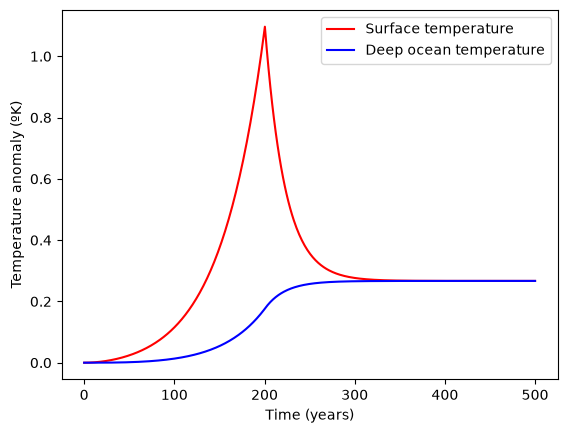

In [160]:
# scenario two
def F(t, exp_timescale=50.0):
    return (np.exp(t / exp_timescale) - 1.0) / (np.exp(200.0 / exp_timescale) - 1.0) if t < 200 else 0.0

Nt = 500
T = np.zeros(Nt)
theta = np.zeros(Nt)
T[0] = 0
theta[0] = 0
t = np.linspace(0, 500, Nt)
dt = t[1] - t[0]

for i in range(0, Nt-1):
    T[i+1] = T[i] + dt * ((F(t[i]) - gamma * (T[i] - theta[i]))/C_s)
    theta[i+1] = theta[i] + dt * ((gamma * (T[i] - theta[i]))/C_d)

plt.plot(t,T,'r-')
plt.plot(t,theta,'b-')
plt.legend(['Surface temperature','Deep ocean temperature'])
plt.xlabel('Time (years)')
plt.ylabel('Temperature anomaly (ºK)')
plt.show()

For scenario two, the exponentional forcing applied again controls the shape of the surface with it initally starting very slow before about 100 years where it starts to "shoot up". This reflects the exponentional nature of the foricng applied. The ocean again responds slowly and reaches a lower value due to the combination of teh type of forcing applied and its slower characteristic timescale.

Forcing scenario 3: 
Let's have two extreme forcing scenarios. One lasting from 0 < t < 150 then anotehr lasting 250 < t < 400

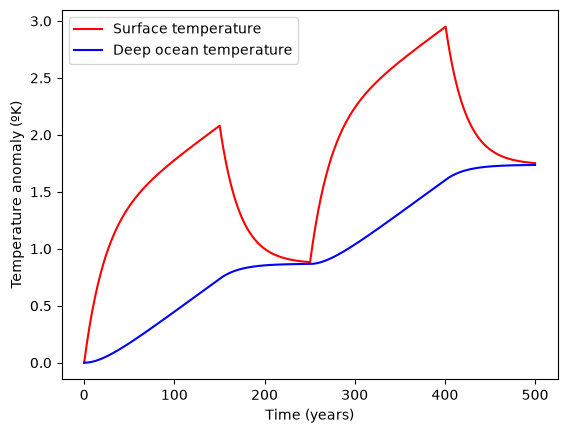

In [161]:
# scenario three
def F(t, exp_timescale=50.0):
    return 1 if t < 150 or 250 < t < 400 else 0

Nt = 500
T = np.zeros(Nt)
theta = np.zeros(Nt)
T[0] = 0
theta[0] = 0
t = np.linspace(0, 500, Nt)
dt = t[1] - t[0]

for i in range(0, Nt-1):
    T[i+1] = T[i] + dt * ((F(t[i]) - gamma * (T[i] - theta[i]))/C_s)
    theta[i+1] = theta[i] + dt * ((gamma * (T[i] - theta[i]))/C_d)

plt.plot(t,T,'r-')
plt.plot(t,theta,'b-')
plt.legend(['Surface temperature','Deep ocean temperature'])
plt.xlabel('Time (years)')
plt.ylabel('Temperature anomaly (ºK)')
plt.show()

For scenario three, the const forcing allows the surface to respond with its typical tau_s we found before (roughly 25 years for 63% of equilibrium value) initally, same with the deep ocean. When the forcing turns off we see recovery of the surface to tend to the deep ocean value, but then we force again from that quasi-equilirium so we increase both surface and atmos again. Interestingly, we have the same time the forcing is set to 150 years, but the shape is slightly more quicker to initally increase from the surface than the first forcing period. We see later a similar quasi-equilbirum state recovered to controlled by the deep ocean again. Shark tooth patterm for surface!

## 2. Diffusion equation

In this part of the project we will solve the 1-D diffusion equation:

$$ \partial_t c = \kappa \partial_x^2 c $$

We will use second order finite differences to approximate the $x$-derivatives, and we will implement and compare two timestepping methods.

Student tasks are in [Section 2.1](#section2pt1) and [Section 2.2](#section2pt2).

First, let's discretize the second order derivative using finite differences. The function below builds a coefficient matrix, $M$, so that $Mc$ is a discretized version of $\partial^2_x c$, where in our discretized version $c$ is a column vector.

In [162]:
    def construct_M(x):
    # Build a coefficient matrix, such that M*c is the discrete version of d^2/dx^2(c)
        dx = x[1] - x[0]  # Infer the uniform grid spacing
        Nx = len(x)  # Number of gridpoints
        M = (np.diag(np.ones(Nx-1), -1) - 2*np.diag(np.ones(Nx), 0) + np.diag(np.ones(Nx-1), 1)) / dx**2
        # Impose dc/dx=0 at both ends using ghost points (c[-1]=c[1] and c[Nx]=c[Nx-2])
        M[0, 1] = 2 / dx**2
        M[-1, -2] = 2 / dx**2
        M = sp.csr_matrix(M) # Turn M into a sparse matrix to save memory and improve speed
        return M

Now, define two functions to timestep the diffusion equation. The code below timesteps the diffusion equation using the expicit Euler method. The function takes in a vector of discrete positions, `x`, discrete times, `t`, and the diffusivity, `kappa`. The vectors `x` and `t` dictate the discretization of the problem in space and time, and the grid spacing must be constant in space and time. The boundary conditions are $\partial_x c=0$ at the starting and ending points in `x`.

In [163]:
def EE(x, t, kappa):
# This function timesteps the diffusion equation with homogeneous Neumann boundary conditions
# using the explicit Euler and second order finite difference methods

    start_time = time.time()  # Start a timer

    # Infer the timestep from the time array
    dt = t[1] - t[0]

    M = construct_M(x)  # Construct the coefficient matrix for the second derivative

    # Set the number of gridpoints in x and t
    Nx = len(x); Nt = len(t)

    # Create an empty sparse array to store the solution
    c = np.zeros((Nx, Nt))

    c[:, 0] = set_ics(x, kappa, 10)  # Set the initial condition

    for k in range(1, Nt):  # loop over the number of timesteps
      c[:,k] = c[:,k-1] + dt * kappa * M @ c[:,k-1] # @ for matrix mult

    end_time = time.time()  # Print the elapsed time

    print(f"Explicit Euler method took {end_time - start_time:.2f} seconds")

    return c

Similarly, the function below timesteps the diffusion equation with the Crank-Nicolson method

In [164]:
def CN(x, t, kappa):
# This function timesteps the diffusion equation with homogeneous Neumann boundary conditions
# using the Crank-Nicolson and second order finite difference methods
    start_time = time.time()  # Start a timer

    # Infer the timestep from the time array
    dt = t[1] - t[0]

    M = construct_M(x)  # Construct the coefficient matrix for the second derivative (including the boundary conditions)

    # Set the number of gridpoints in x and t
    Nx = len(x); Nt = len(t)

    A = sp.eye(Nx) - 0.5 * dt * kappa * M  # This matrix appears on the LHS in the C-N scheme
    A_solve = spla.factorized(A.tocsc()) # LU-factorize A (this only needs to be done once)

    # Create an empty sparse array to store the solution
    c = np.zeros((Nx, Nt))

    c[:, 0] = set_ics(x, kappa, 10)  # Set the initial condition

    for k in range(1, Nt): # loop over the number of timesteps
        c[:, k] = A_solve(c[:, k-1] + 0.5 * dt * kappa * (M @ c[:, k-1]))

    end_time = time.time()  # Print the elapsed time

    print(f"Crank-Nicolson method took {end_time - start_time:.2f} seconds")

    return c

Next, create a function to set the initial conditions. The exact solution to the unbounded diffusion equation with a delta function initial condition is:

$$\left(\frac{1}{4\pi\kappa t}\right)^{1/2}e^{-x^2/(4\kappa t)}$$

The function below sets the initial condition by evaluating the exact solution at a given time. Note that it is important that we don't evaluate the exact solution at `t_ic=0` since this will return a delta function which will be undefined on our finite grid. The value of `t_ic` is set within the `EE` and `CN` functions.

In [165]:
# Function to set the initial condition from the exact solution at time t_start
def set_ics(x, kappa, t_ic):
    c_ic = (4*np.pi*kappa*t_ic)**(-0.5)*np.exp(-x**2 / (4*kappa*t_ic))
    return c_ic


Finally, define some parameters and the x and t vectors:

In [166]:
# Defining parameters
kappa = 0.001  # diffusivity

# Timestepping parameters
t_start = 0  # start time (note that this is not the same time used to evaluate the exact solution to set the ICs)
t_end = 10  # end time
Nt = 1000  # number of timesteps

# Size of the physical domain
x_start = -1
x_end = 1
Nx = 100

t = np.linspace(t_start, t_end, Nt)  # Create a vector of times
x = np.linspace(x_start, x_end, Nx)  # Create a vector for x

Run each method once:

In [167]:
# Run the simulations
c_EE = EE(x, t, kappa) # explicit Euler
c_CN = CN(x, t, kappa) # Crank-Nicolson

Explicit Euler method took 0.05 seconds
Crank-Nicolson method took 0.04 seconds


and finally, plot the results side-by-side

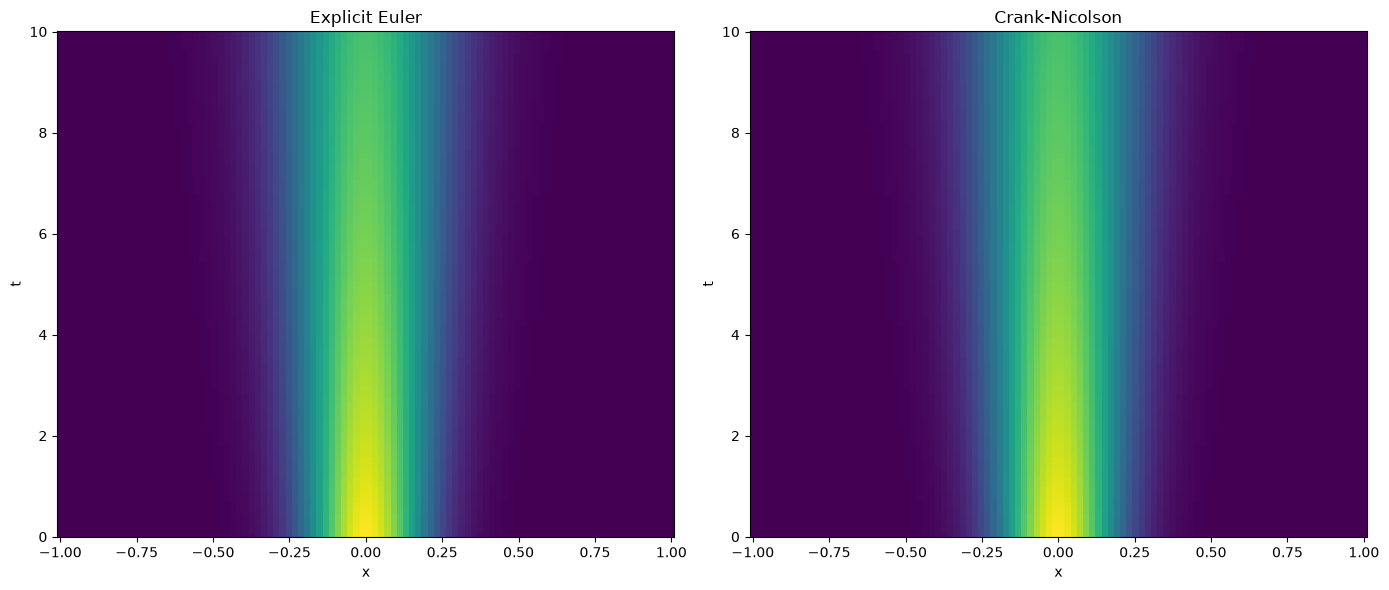

In [168]:
# Plot the results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.pcolormesh(x, t, c_EE.T, shading='auto')
plt.xlabel('x')
plt.ylabel('t')
plt.title('Explicit Euler')

plt.subplot(1, 2, 2)
plt.pcolormesh(x, t, c_CN.T, shading='auto')
plt.xlabel('x')
plt.ylabel('t')
plt.title('Crank-Nicolson')

plt.tight_layout()
plt.show()

## 2. Student investigation

### 2.1 Stability
<a id='section2pt1'></a>
The explicit Euler and Crank-Nicolson methods have different stability properties. To explore this, try increasing the diffusivity, $\kappa$, and see how each method responds. Discuss your findings below (~2-3 sentences).

Starting case:
![alt text](image-2.png)

- here both methods show the same output, with Euler taking marginally more time:
    Explicit Euler method took 0.06 seconds
    Crank-Nicolson method took 0.02 seconds

When increasing kappa to 0.1, Euler does not work. For t approx 3.5 then the plot becomes:
![alt text](image.png)
This to me suggests that teh Euler method became unstable for this kappa and crashed.

I also tested kappa = 0.031 as the last kappa that gave a non-crash reuslt for Euler
![alt text](image-1.png)


We aren't changing the timesteps, but making kappa bigger which make sthe diffusion process larger - so there is a discrepancy between the effect and the timescales each method can model. Thus, we are looking at the trade off of number of timesteps and efficiency in the computational cost.

It seems that CN is broadly more stable to changes in kappa (increases) than EE for fixed timesteps.

### 2.2 Accuracy
<a id='section2pt2'></a>
Next, we will examine the accuracy of the numerical methods used above. In order to do this, it is useful to compare our numerical solutions with the exact solution to the diffusion equation. Below, write code to plot the exact solution and the numerical solution using explicit Euler and Crank-Nicolson at the final time ($t=10$). Note that you can use the exact solution to the diffusion equation in an unbounded domain in $x$ and keep in mind that the exact solution and numerical solutions will differ for later times when boundary effects are felt.

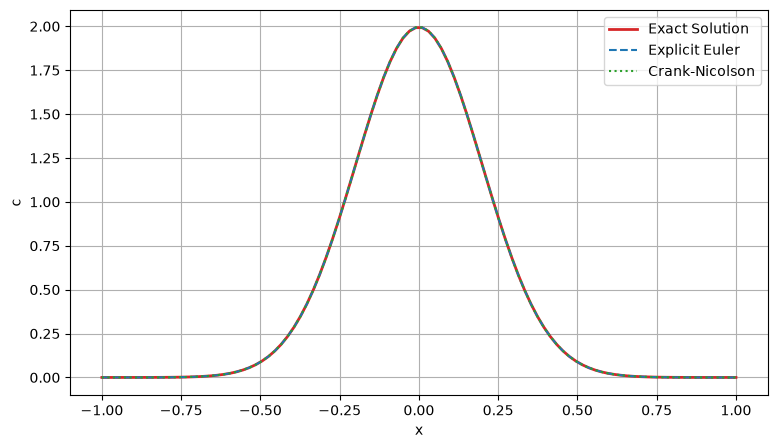

In [169]:
# Add code to plot exact and numerical solutions
exact_solution = set_ics(x, kappa, 10 + t[-1])
EE_solution = c_EE[:,-1]
CN_solution = c_CN[:,-1]

plt.figure(figsize=(9, 5))
plt.plot(x, exact_solution, label='Exact Solution', color='tab:red', lw=2)
plt.plot(x, EE_solution, label='Explicit Euler', color='tab:blue', ls="dashed")
plt.plot(x, CN_solution, label='Crank-Nicolson', color='tab:green', ls="dotted")

plt.xlabel('x')
plt.ylabel('c')
plt.legend()
plt.grid()

plt.show()

The difference between the exact solution and the numerical approximation can be quantified by various measures of error. The *local error* is the difference between the exact solution and the numerical approximation after one timestep. The *global error* is the difference between the solutions after a fixed amount of time (which includes the accumulation of multiple steps of local error). A method is first order accurate if the global error is linearly proportional to the timestep. A method is second order accurate if the global error varies quadratically with the timestep. Below, calculate and plot the global error for the Explicit Euler and Crank-Nicolson methods and use your results to infer the order of accuracy of each scheme.

PLOT GLOBAL ERROR FOR EACH SCHEME (1-2 figures) AND DISCUSS ORDER OF ACCURACY (2-3 sentences)

Crank-Nicolson method took 0.24 seconds
Explicit Euler method took 0.00 seconds
Crank-Nicolson method took 0.00 seconds
Explicit Euler method took 0.01 seconds
Crank-Nicolson method took 0.01 seconds
Explicit Euler method took 0.01 seconds
Crank-Nicolson method took 0.01 seconds
Explicit Euler method took 0.02 seconds
Crank-Nicolson method took 0.02 seconds
Explicit Euler method took 0.05 seconds
Crank-Nicolson method took 0.03 seconds
Explicit Euler method took 0.08 seconds
Crank-Nicolson method took 0.06 seconds
Explicit Euler method took 0.09 seconds
Crank-Nicolson method took 0.06 seconds
Explicit Euler method took 0.12 seconds
Crank-Nicolson method took 0.07 seconds
Explicit Euler method took 0.16 seconds
Crank-Nicolson method took 0.09 seconds
Explicit Euler method took 0.21 seconds
Crank-Nicolson method took 0.11 seconds
Explicit Euler method took 0.20 seconds
Crank-Nicolson method took 0.13 seconds
Gradient for EE: 1.00
Gradient for CN: 2.16


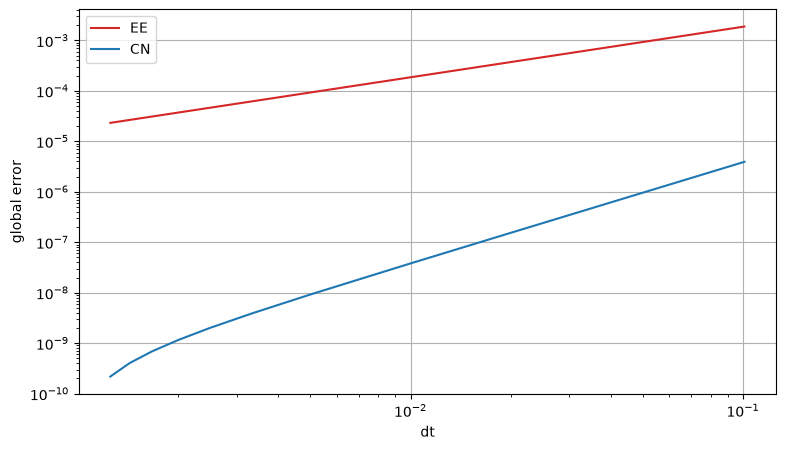

In [184]:
# Add code to plot error here
# plot a graph of difference in solution vs timesteps, so we need to vary timesteps
Nt_values = [100, 250, 500, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000] # different total numbers of dt
dt_values = []
error_in_EE = []
error_in_CN = []

time_ref = np.linspace(t_start, t_end, 10000) # lots of time steps for the exact soln
# c_exact = set_ics(x, kappa, 10 + t[-1])
# need to use a "reference" that makes sure we only look at the time error not spatial
c_ref = CN(x, time_ref, kappa)[:, -1]

for Nt_i in Nt_values:
    t_i = np.linspace(t_start, t_end, Nt_i)
    dt_i = t_i[1] - t_i[0]
    dt_values.append(dt_i)

    c_EE_i = EE(x, t_i, kappa)[:,-1]
    c_CN_i = CN(x, t_i, kappa)[:,-1]

    # global error = difference at t_end
    error_in_EE.append(np.max(np.abs(c_EE_i - c_ref)))
    error_in_CN.append(np.max(np.abs(c_CN_i - c_ref)))

plt.figure(figsize=(9, 5))
plt.loglog(dt_values, error_in_EE, label='EE', color='tab:red')
plt.loglog(dt_values, error_in_CN, label='CN', color='tab:blue')

# work out the gradient of each of these in loglog & print
log_dt = np.log(dt_values)
slope_EE, _ = np.polyfit(log_dt, np.log(error_in_EE), 1)
slope_CN, _ = np.polyfit(log_dt, np.log(error_in_CN), 1)
print(f"Gradient for EE: {slope_EE:.2f}")
print(f"Gradient for CN: {slope_CN:.2f}")

plt.xlabel("dt")
plt.ylabel("global error")
plt.legend()
plt.grid()

plt.show()

On a log-log plot of global error versus timestep size (dt), the slope of error curve shows order of accuracy. EE has slope 1, so it is first order accurate in time. CN has slope 2.16, so it is second order accurate in time, but this appears to break down at very small dt with a small curve visible that has edited the gradient to be slightly above 2.

Finally, select a given error tolerance and explore whether explicit Euler or Crank-Nicoslon is more efficient (faster) at generating solutions with error less than your error tolerance. Discuss your conclusion and add supporting figures if necessary.

INSERT DISCUSSION OF ERROR HERE (~1 paragraph).  OPTIONALLY ADD PLOTS BY INSERTING A CODE BLOCK BELOW.